# Fase 1 (versión corregida) — Análisis Exploratorio de Datos
## MATERNA · Sistema de alerta temprana de riesgo materno-perinatal en zonas dispersas y comunidades indígenas
**Proyecto de aula — Inteligencia Artificial · Universidad Popular del Cesar**

Este notebook reemplaza al EDA entregado en la Fase 1 y corrige estas inconsistencias:

| # | Inconsistencia en la versión anterior | Corrección |
|---|---|---|
| 1 | El notebook analizaba el dataset público UCI *Maternal Health Risk* (1.014 registros), mientras que el documento describía el dataset propio de La Guajira y Cesar. | El EDA se hace sobre `dataset_riesgo_materno_guajira_cesar.csv` (1.200 registros), que es el dataset que se modela. |
| 2 | La conclusión decía que no había duplicados relevantes, cuando la celda mostraba 562 (55,4 %) en el dataset UCI. | Se reporta lo que muestran las celdas. El dataset propio no tiene duplicados. |
| 3 | Se afirmaba un desbalance que exigía balanceo, aunque la diferencia (13,2 pp) estaba por debajo del umbral definido (15–20 pp). | Aquí el desbalance sí es relevante: Alto Riesgo = 12,7 %. |
| 4 | El documento afirmaba que los nulos se concentraban en el área rural dispersa. | Se verifica con los datos (sección 4.1): no es así en la glucosa. |
| 5 | El CSV termina cada línea en coma y genera una columna vacía `Unnamed: 16`. | Se elimina al cargar (`src/data_preprocessing.py`). |

> **Naturaleza de los datos.** El dataset es **sintético**: lo generó el equipo con reglas probabilísticas calibradas con proporciones del DANE y del INS. No contiene historias clínicas reales. Las conclusiones describen el comportamiento del dataset y no deben leerse como evidencia epidemiológica.

## 0. Librerías y carga

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

from src.data_preprocessing import cargar_dataset, reporte_calidad
from src.config import NOMBRES_CLASES

df_crudo = pd.read_csv(RAIZ / "data/raw/dataset_riesgo_materno_guajira_cesar.csv")
print("Columnas del CSV original:", list(df_crudo.columns))
df = cargar_dataset()
print(f"\nTras la limpieza estructural: {df.shape[0]} registros x {df.shape[1]} variables")
df.head()

Columnas del CSV original: ['id_gestante', 'edad', 'departamento', 'municipio', 'pertenencia_etnica', 'area_residencia', 'semanas_gestacion', 'n_controles_prenatales', 'atendido_por', 'pas_mmhg', 'pad_mmhg', 'fcf_bpm', 'glucosa_mgdl', 'proteinuria', 'convulsiones', 'riesgo_obstetrico', 'Unnamed: 16']

Tras la limpieza estructural: 1200 registros x 16 variables


,id_gestante,edad,departamento,municipio,pertenencia_etnica,area_residencia,semanas_gestacion,n_controles_prenatales,atendido_por,pas_mmhg,pad_mmhg,fcf_bpm,glucosa_mgdl,proteinuria,convulsiones,riesgo_obstetrico
0,G0001,19,Cesar,Codazzi,Mestiza,Rural disperso,32,3,Medico,109,86,146.6,113.4,0,0,Bajo Riesgo
1,G0002,28,La Guajira,Manaure,Mestiza,Rural disperso,26,2,Enfermero(a),117,83,122.5,203.4,0,0,Riesgo Medio
2,G0003,21,Cesar,La Paz,Mestiza,Rural disperso,39,3,Medico,119,71,134.0,60.0,0,0,Bajo Riesgo
3,G0004,15,Cesar,La Paz,Afro,Cabecera,31,4,Medico,100,72,140.6,74.4,0,0,Riesgo Medio
4,G0005,23,La Guajira,Uribia,Mestiza,Cabecera,35,3,Medico,103,72,129.8,NaN,0,0,Bajo Riesgo


## 1. Descripción del dataset

| Variable | Descripción | Tipo |
|---|---|---|
| `id_gestante` | Identificador (no predictivo) | Texto |
| `edad` | Edad de la gestante (años) | Numérica |
| `departamento`, `municipio` | Ubicación (2 departamentos, 8 municipios) | Categórica |
| `pertenencia_etnica` | Wayuu, Mestiza, Afro, Yukpa, Arhuaco, Wiwa, Kogui | Categórica |
| `area_residencia` | Cabecera / Rural disperso | Categórica |
| `semanas_gestacion` | Edad gestacional (semanas) | Numérica |
| `n_controles_prenatales` | Controles prenatales previos | Numérica discreta |
| `atendido_por` | Médico, Enfermero(a), Auxiliar de enfermería, Partera tradicional | Categórica |
| `pas_mmhg`, `pad_mmhg` | Presión arterial sistólica / diastólica | Numérica |
| `fcf_bpm` | Frecuencia cardiaca fetal (lpm) | Numérica (con nulos) |
| `glucosa_mgdl` | Glucosa (mg/dL) | Numérica (con nulos) |
| `proteinuria` | Tira reactiva: 0 = negativa, 1 = +, 2 = ++ | Ordinal |
| `convulsiones` | Presencia de convulsiones | Binaria |
| `riesgo_obstetrico` | **Objetivo**: Bajo Riesgo / Riesgo Medio / Alto Riesgo | Categórica ordinal |

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_gestante             1200 non-null   str    
 1   edad                    1200 non-null   int64  
 2   departamento            1200 non-null   str    
 3   municipio               1200 non-null   str    
 4   pertenencia_etnica      1200 non-null   str    
 5   area_residencia         1200 non-null   str    
 6   semanas_gestacion       1200 non-null   int64  
 7   n_controles_prenatales  1200 non-null   int64  
 8   atendido_por            1200 non-null   str    
 9   pas_mmhg                1200 non-null   int64  
 10  pad_mmhg                1200 non-null   int64  
 11  fcf_bpm                 1111 non-null   float64
 12  glucosa_mgdl            1041 non-null   float64
 13  proteinuria             1200 non-null   int64  
 14  convulsiones            1200 non-null   int64  
 15

In [3]:
for clave, valor in reporte_calidad(df).items():
    print(f"{clave}: {valor}")

registros: 1200
columnas: 16
ids_duplicados: 0
filas_duplicadas_sin_id: 0
nulos: {'fcf_bpm': 89, 'glucosa_mgdl': 159}
pct_nulos: {'fcf_bpm': 7.42, 'glucosa_mgdl': 13.25}
fuera_de_rango_fisiologico: {}
distribucion_target: {'Bajo Riesgo': 578, 'Riesgo Medio': 470, 'Alto Riesgo': 152}


## 2. Estadísticas descriptivas

In [4]:
numericas = ["edad", "semanas_gestacion", "n_controles_prenatales", "pas_mmhg", "pad_mmhg", "fcf_bpm", "glucosa_mgdl"]
desc = df[numericas].describe().T
desc["asimetría"] = df[numericas].skew()
desc["curtosis"] = df[numericas].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
edad,1200.0,25.30,6.20,14.0,21.0,25.0,30.0,43.0,0.21,-0.49
semanas_gestacion,1200.0,27.70,6.63,7.0,23.0,28.0,32.0,41.0,-0.15,-0.27
n_controles_prenatales,1200.0,3.07,1.95,0.0,1.0,3.0,5.0,6.0,-0.15,-1.15
pas_mmhg,1200.0,116.55,16.72,85.0,106.0,113.0,123.0,185.0,1.38,2.35
pad_mmhg,1200.0,74.76,11.25,50.0,67.0,73.0,79.0,117.0,1.04,1.26
fcf_bpm,1111.0,140.09,14.10,90.0,130.8,140.2,149.5,180.0,-0.06,0.07
glucosa_mgdl,1041.0,104.17,30.34,60.0,83.0,98.6,119.1,210.0,1.07,1.15


In [5]:
orden = ["Bajo Riesgo", "Riesgo Medio", "Alto Riesgo"]
df.groupby("riesgo_obstetrico")[numericas + ["proteinuria", "convulsiones"]].mean().reindex(orden).round(2)

,edad,semanas_gestacion,n_controles_prenatales,pas_mmhg,pad_mmhg,fcf_bpm,glucosa_mgdl,proteinuria,convulsiones
riesgo_obstetrico,,,,,,,,,
Bajo Riesgo,25.17,27.89,3.59,111.65,71.31,138.40,96.62,0.00,0.00
Riesgo Medio,25.58,27.56,2.58,113.60,73.39,141.84,112.00,0.16,0.00
Alto Riesgo,24.95,27.43,2.61,144.28,92.13,140.83,107.77,0.97,0.04


In [6]:
for col in ["departamento", "municipio", "pertenencia_etnica", "area_residencia", "atendido_por"]:
    print(f"\n{col}:\n", (df[col].value_counts(normalize=True) * 100).round(1).to_string())


departamento:
 departamento
La Guajira    64.1
Cesar         35.9

municipio:
 municipio
Uribia        26.4
Valledupar    16.4
Riohacha      14.4
Manaure       13.3
Maicao         9.9
Codazzi        8.8
La Paz         6.1
Becerril       4.6

pertenencia_etnica:
 pertenencia_etnica
Wayuu      47.0
Mestiza    30.8
Afro       10.0
Yukpa       6.2
Arhuaco     2.6
Wiwa        1.7
Kogui       1.7

area_residencia:
 area_residencia
Rural disperso    58.4
Cabecera          41.6

atendido_por:
 atendido_por
Medico                    71.6
Partera tradicional       11.5
Auxiliar de enfermeria     9.2
Enfermero(a)               7.7


## 3. Visualizaciones

### 3.1 Distribución de la variable objetivo

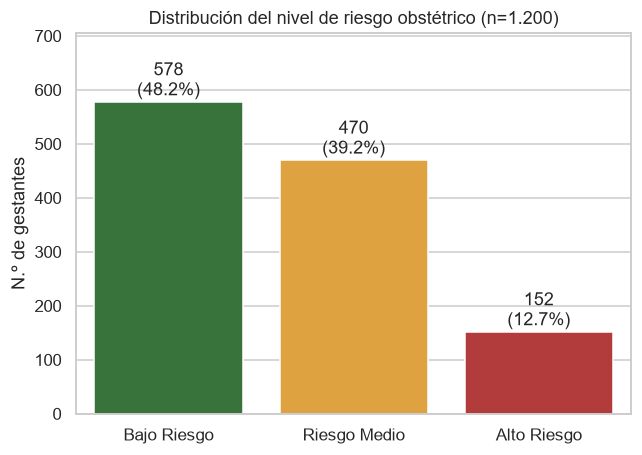

In [7]:
paleta = {"Bajo Riesgo": "#2E7D32", "Riesgo Medio": "#F9A825", "Alto Riesgo": "#C62828"}
conteo = df["riesgo_obstetrico"].value_counts().reindex(orden)
fig, ax = plt.subplots(figsize=(6, 4.3))
sns.barplot(x=conteo.index, y=conteo.values, hue=conteo.index, palette=paleta, legend=False, ax=ax)
ax.set_ylim(0, conteo.max() * 1.22)
for i, v in enumerate(conteo.values):
    ax.text(i, v + 12, f"{v}\n({v / len(df):.1%})", ha="center")
ax.set_title("Distribución del nivel de riesgo obstétrico (n=1.200)")
ax.set_xlabel(""); ax.set_ylabel("N.º de gestantes")
plt.tight_layout(); plt.show()

### 3.2 Presión arterial sistólica vs. diastólica (umbrales 140/90 y 160/110 mmHg)

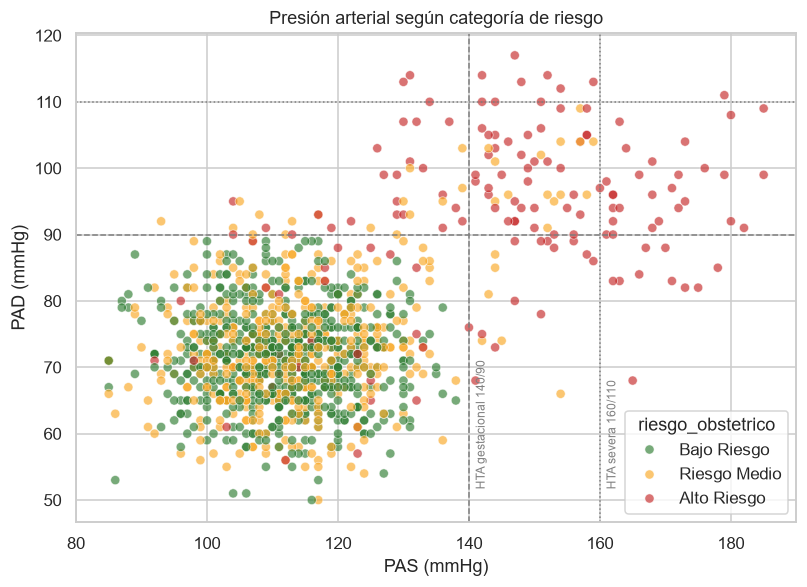

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(data=df, x="pas_mmhg", y="pad_mmhg", hue="riesgo_obstetrico", hue_order=orden, palette=paleta, alpha=0.65, ax=ax)
for x, y, estilo, txt in [(140, 90, "--", "HTA gestacional 140/90"), (160, 110, ":", "HTA severa 160/110")]:
    ax.axvline(x, color="grey", ls=estilo, lw=1); ax.axhline(y, color="grey", ls=estilo, lw=1)
    ax.text(x + 1, 52, txt, fontsize=8, color="grey", rotation=90)
ax.set_xlabel("PAS (mmHg)"); ax.set_ylabel("PAD (mmHg)")
ax.set_title("Presión arterial según categoría de riesgo")
plt.tight_layout(); plt.show()

### 3.3 Variables clínicas por nivel de riesgo

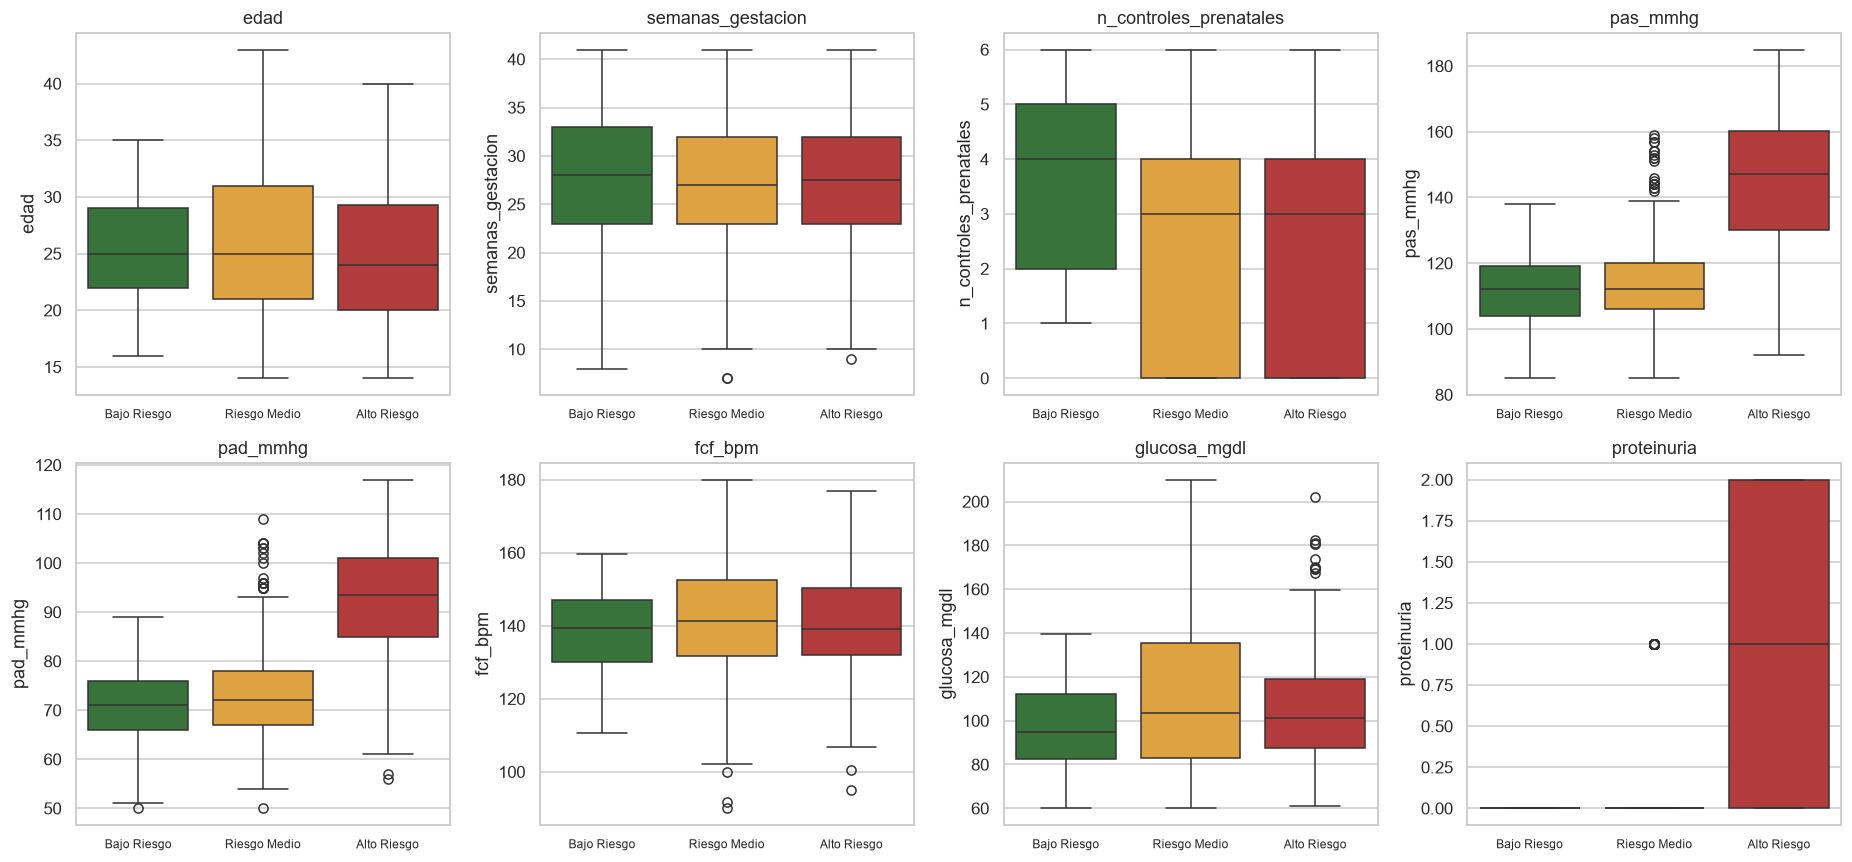

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, col in zip(axes.flat, numericas + ["proteinuria"]):
    sns.boxplot(data=df, x="riesgo_obstetrico", y=col, order=orden, hue="riesgo_obstetrico", palette=paleta, legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

### 3.4 Factores de acceso: controles prenatales y área de residencia

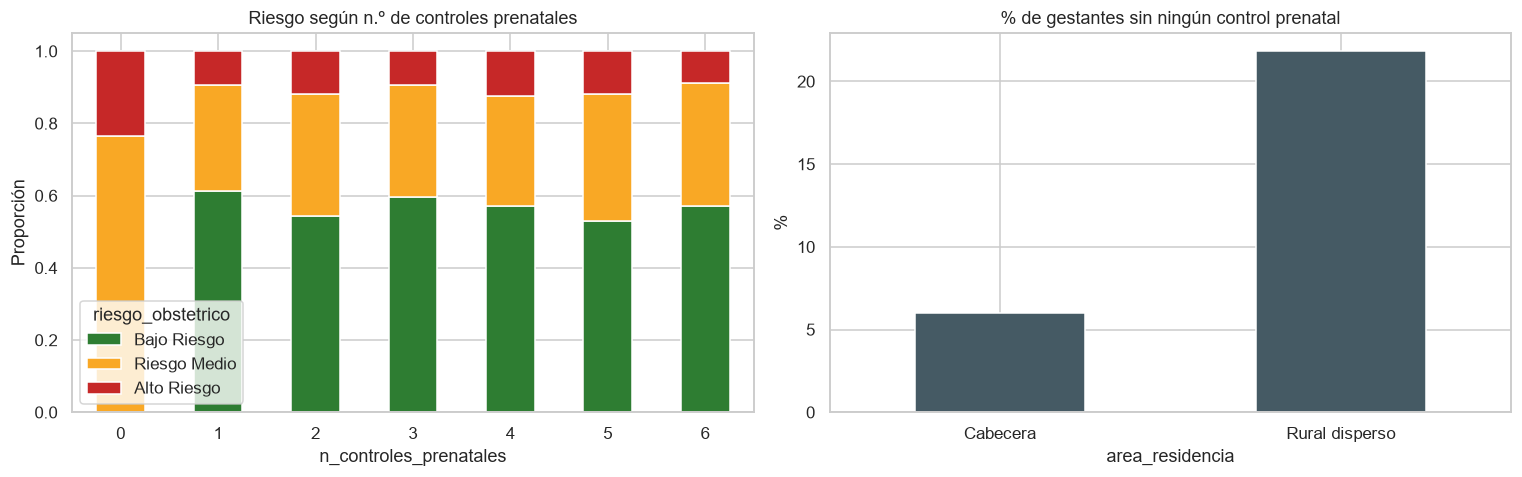

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pd.crosstab(df["n_controles_prenatales"], df["riesgo_obstetrico"], normalize="index")[orden].plot(
    kind="bar", stacked=True, color=[paleta[c] for c in orden], ax=axes[0])
axes[0].set_title("Riesgo según n.º de controles prenatales"); axes[0].set_ylabel("Proporción")
pd.crosstab(df["area_residencia"], df["n_controles_prenatales"] == 0, normalize="index")[True].mul(100).plot(
    kind="bar", color="#455A64", ax=axes[1])
axes[1].set_title("% de gestantes sin ningún control prenatal"); axes[1].set_ylabel("%")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 3.5 Matriz de correlación

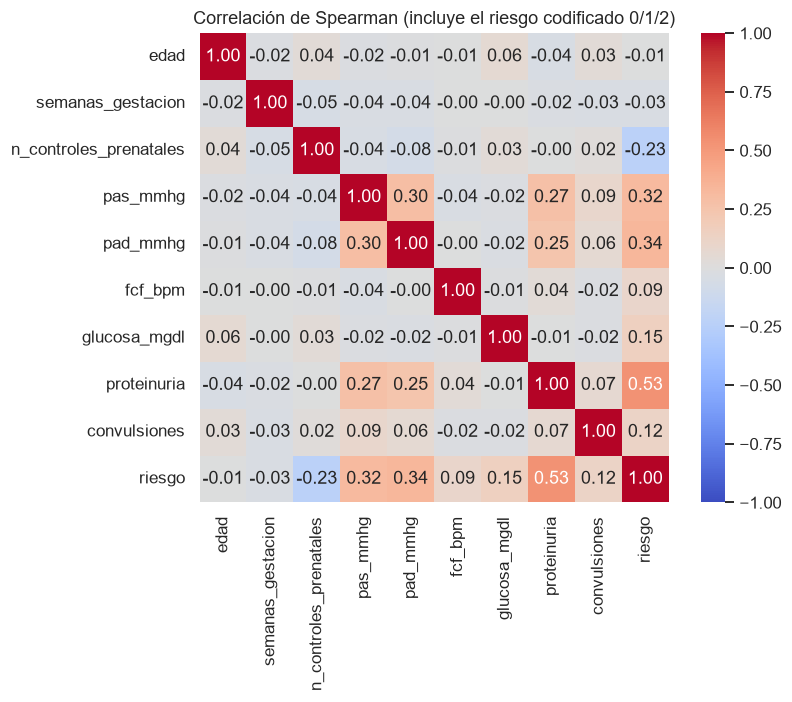

In [11]:
plt.figure(figsize=(8, 6.5))
corr = df[numericas + ["proteinuria", "convulsiones"]].assign(riesgo=df["riesgo_obstetrico"].map({c: i for i, c in enumerate(orden)})).corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Spearman (incluye el riesgo codificado 0/1/2)")
plt.tight_layout(); plt.show()

## 4. Calidad de los datos
### 4.1 Valores nulos y su patrón

In [12]:
nulos = pd.DataFrame({"nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(2)})
display(nulos[nulos["nulos"] > 0])
patron = pd.concat({
    "por área": df.groupby("area_residencia")[["glucosa_mgdl", "fcf_bpm"]].agg(lambda s: s.isna().mean() * 100),
    "por riesgo": df.groupby("riesgo_obstetrico")[["glucosa_mgdl", "fcf_bpm"]].agg(lambda s: s.isna().mean() * 100),
}).round(1)
patron.columns = ["% nulos glucosa", "% nulos FCF"]
patron

,nulos,% nulos
fcf_bpm,89,7.42
glucosa_mgdl,159,13.25


% nulos glucosa  % nulos FCF
por área   Cabecera                   14.2          6.0
           Rural disperso             12.6          8.4
por riesgo Alto Riesgo                14.5          7.2
           Bajo Riesgo                14.5          9.5
           Riesgo Medio               11.3          4.9

**Hallazgo (corrige el documento de la Fase 1):** la glucosa tiene **más** nulos en cabecera (14,2 %) que en el área rural dispersa (12,6 %). En la FCF los nulos son algo más frecuentes en el área rural (8,4 % frente a 6,0 %), pero la diferencia es pequeña. El patrón es compatible con datos **faltantes al azar (MCAR/MAR)**, no con una concentración rural. En la Fase 2 se imputa con la mediana estratificada por área y trimestre, y se agrega un indicador `*_no_disponible`, porque en campo real la ausencia del examen sí puede depender del acceso.

### 4.2 Valores atípicos (criterio IQR) frente a rangos fisiológicos

In [13]:
def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(), q1 - 1.5 * iqr, q3 + 1.5 * iqr

filas = []
for col in numericas:
    n, lo, hi = outliers_iqr(df[col].dropna())
    filas.append({"variable": col, "outliers_IQR": n, "% ": round(n / df[col].notna().sum() * 100, 1),
                  "lím_inf": round(lo, 1), "lím_sup": round(hi, 1), "mín": df[col].min(), "máx": df[col].max()})
pd.DataFrame(filas)

,variable,outliers_IQR,%,lím_inf,lím_sup,mín,máx
0,edad,0,0.0,7.5,43.5,14.0,43.0
1,semanas_gestacion,5,0.4,9.5,45.5,7.0,41.0
2,n_controles_prenatales,0,0.0,-5.0,11.0,0.0,6.0
3,pas_mmhg,80,6.7,80.5,148.5,85.0,185.0
4,pad_mmhg,64,5.3,49.0,97.0,50.0,117.0
5,fcf_bpm,8,0.7,102.8,177.5,90.0,180.0
6,glucosa_mgdl,53,5.1,28.9,173.2,60.0,210.0


In [14]:
atipicos_pas = df[df["pas_mmhg"] > 148.5]
print("Gestantes con PAS por encima del límite IQR, por categoría:")
print(atipicos_pas["riesgo_obstetrico"].value_counts().to_string())

Gestantes con PAS por encima del límite IQR, por categoría:
riesgo_obstetrico
Alto Riesgo     69
Riesgo Medio    11


Los outliers de presión arterial (80 en PAS, 64 en PAD) y de glucosa (53) **son clínicamente plausibles**: crisis hipertensivas y probable diabetes gestacional, casi todos en Riesgo Medio/Alto. **No se eliminan.** En la Fase 2 se usa `RobustScaler`, que escala con la mediana y el IQR. Ningún valor está fuera de rango fisiológico, así que no hay errores evidentes de captura.

### 4.3 Duplicados

In [15]:
print("IDs duplicados:", df["id_gestante"].duplicated().sum())
print("Filas duplicadas (ignorando el ID):", df.drop(columns="id_gestante").duplicated().sum())

IDs duplicados: 0
Filas duplicadas (ignorando el ID): 0


### 4.4 Desbalance de clases

In [16]:
prop = df["riesgo_obstetrico"].value_counts(normalize=True).reindex(orden) * 100
print(prop.round(1).astype(str) + " %")
print(f"\nRazón mayoritaria/minoritaria: {prop.max() / prop.min():.1f} : 1  |  diferencia: {prop.max() - prop.min():.1f} pp")

riesgo_obstetrico
Bajo Riesgo     48.2 %
Riesgo Medio    39.2 %
Alto Riesgo     12.7 %
Name: proportion, dtype: str

Razón mayoritaria/minoritaria: 3.8 : 1  |  diferencia: 35.5 pp


### 4.5 Relación entre las etiquetas y los umbrales clínicos
Verificamos si las reglas de seguridad que propone el proyecto (PAS ≥ 160, PAD ≥ 110, convulsiones o proteinuria ++) coinciden con la etiqueta.

In [17]:
from src.clinical_rules import mascara_reglas
regla = mascara_reglas(df)
pd.crosstab(pd.Series(regla, name="regla crítica activa"), df["riesgo_obstetrico"])[orden]

riesgo_obstetrico,Bajo Riesgo,Riesgo Medio,Alto Riesgo
regla crítica activa,,,
False,578,470,63
True,0,0,89


Las **89** gestantes que activan una regla crítica están todas etiquetadas como Alto Riesgo. Eso es así porque **las etiquetas sintéticas se generaron con esos mismos umbrales**. Esto tiene dos consecuencias para la Fase 2:
1. El motor híbrido acertará esos casos *por construcción*, así que su desempeño en ellos no prueba nada sobre datos reales.
2. Para medir el aporte real del modelo estadístico, la evaluación se reporta también en el subconjunto **sin** signos críticos.

Además, la etnia y el municipio casi no cambian la distribución de riesgo (Alto Riesgo: 12,1 % en Cesar frente a 13,0 % en La Guajira). Esto respalda dejarlas fuera del modelo y usarlas solo para auditar sesgos.

In [18]:
pd.crosstab(df["pertenencia_etnica"], df["riesgo_obstetrico"], normalize="index")[orden].mul(100).round(1)

riesgo_obstetrico,Bajo Riesgo,Riesgo Medio,Alto Riesgo
pertenencia_etnica,,,
Afro,46.7,42.5,10.8
Arhuaco,45.2,38.7,16.1
Kogui,40.0,50.0,10.0
Mestiza,49.7,37.6,12.7
Wayuu,47.3,40.2,12.4
Wiwa,45.0,35.0,20.0
Yukpa,53.3,32.0,14.7


## 5. Conclusiones del EDA
1. **Calidad estructural adecuada.** 1.200 registros, sin duplicados ni valores fuera de rango fisiológico. Hay que eliminar la columna vacía `Unnamed: 16`.
2. **Nulos.** Glucosa 13,25 % y FCF 7,42 %, sin concentración rural clara en la glucosa. Se imputan sin fuga de datos (mediana por área × trimestre, ajustada solo en entrenamiento) y con indicadores de no disponibilidad.
3. **Outliers clínicos reales.** Se conservan y se usa `RobustScaler`.
4. **Desbalance moderado.** Alto Riesgo representa el 12,7 % (razón 3,8 : 1). En la Fase 2 se compara SMOTE (dentro de cada fold) con `class_weight='balanced'`.
5. **Separabilidad.** PAS, PAD, proteinuria, controles prenatales, glucosa y edad son las variables más asociadas al riesgo, coherente con la GPC de Minsalud y con la literatura del estado del arte.
6. **Limitación central.** Las etiquetas sintéticas siguen umbrales deterministas, así que las métricas de la Fase 2 miden qué tan bien el modelo reproduce esas reglas, no su desempeño clínico. Para validarlo hace falta un dataset real anonimizado, obtenido mediante una alianza con una ESE/IPS.